# Практическая работа № 3. Анализ данных и визуализация средствами R

**ИТАиОД · вариант 7 · R**

Воспроизводим базовую графику по методичке и [главе 5 учебного пособия Т. Е. Самсонова](https://tsamsonov.github.io/r-geo-course/05-BaseGraphics.html). Для варианта 7 анализируем квартальный ряд `austres` и ответы волны 2022 из [Stack Overflow Developer Survey 2011–2022](https://www.kaggle.com/datasets/yasirabdaali/stack-overflow-developer-survey-20112022).

Запустите все ячейки в ядре R. Нужны пакеты `readxl`, `RColorBrewer` и `dplyr`. При работе без интернета задайте каталог с `ExpImp.xlsx` и `oxr_vod.csv` через `ITAIOD_GEO_DATA_DIR` и путь к CSV волны 2022 через `ITAIOD_SURVEY_CSV`.

В CSV за 2022 год из архива Kaggle обнаружен повреждённый участок. Для этой волны используется [оригинальная публикация Stack Overflow](https://survey.stackoverflow.co/2022/).

## 1. Данные для примеров методички

Загружаем экспорт и импорт за 2013 год в млн долл. США и сброс сточных вод в млрд м³. Для торговли отделяем строки федеральных округов от строк субъектов. В Excel символ `-` обозначает отсутствующее числовое значение. Таблицы опубликованы в [репозитории пособия](https://github.com/tsamsonov/r-geo-course/tree/master/data).

In [1]:
suppressPackageStartupMessages(library(dplyr))
options(repr.plot.width = 10, repr.plot.height = 5.5, scipen = 8)

# Читает исходный файл через переданную функцию. Если локальной копии нет,
# загружает опубликованный файл во временный каталог и удаляет после чтения.
read_geo_data <- function(filename, reader) {
  locations <- file.path(
    c(Sys.getenv("ITAIOD_GEO_DATA_DIR", unset = "data"), "data", "../data"),
    filename
  )
  existing <- locations[file.exists(locations)]
  if (length(existing) > 0L) {
    return(reader(existing[[1L]]))
  }
  path <- tempfile(fileext = paste0(".", tools::file_ext(filename)))
  on.exit(unlink(path))
  base_url <- "https://raw.githubusercontent.com/tsamsonov/r-geo-course/master/data/"
  download.file(paste0(base_url, filename), path, mode = "wb", quiet = TRUE)
  reader(path)
}

trade <- read_geo_data("ExpImp.xlsx", function(path) {
  as.data.frame(readxl::read_excel(
    path, sheet = 1, col_types = c("text", rep("numeric", 12)),
    na = c("", "-", "…", "...")
  ))
})
water <- read_geo_data("oxr_vod.csv", function(path) {
  read.csv2(path, encoding = "UTF-8")
})
districts <- trade[grep("федеральный округ", trade$Регион), ]
districts <- districts[order(districts$Регион), ]
regions <- trade[!grepl("федеральный округ|Федерация|числе", trade$Регион), ]
district_labels <- trimws(sub("федеральный округ", "", districts$Регион))

str(trade)
print(head(water))

'data.frame':	96 obs. of  13 variables:
 $ Регион     : chr  "Российская Федерация" "Центральный федеральный округ" "Белгородская область" "Брянская область" ...
 $ ПродЭкспорт: num  16196.2 4552.9 221.9 28.5 177.9 ...
 $ ПродИмпорт : num  43076 22954 614 650 454 ...
 $ ТЭКЭкспорт : num  371791.8 204331.7 64.7 5 0.9 ...
 $ ТЭКИмпорт  : num  3613.6 1660.3 24.1 20.5 16.7 ...
 $ ХимЭкспорт : num  30739.2 8442.7 33.3 24.5 87.7 ...
 $ ХимИмпорт  : num  50129.5 34870.4 242.8 71.7 419 ...
 $ ДревЭкспорт: num  10965.8 1101.6 6.2 23.4 57.1 ...
 $ ДревИмпорт : num  6641.5 3942.6 43.3 44.9 9 ...
 $ МетЭкспорт : num  40859.3 9877 2014.1 50.5 29 ...
 $ МетИмпорт  : num  22017.4 11763.6 1207.3 68.3 56.6 ...
 $ МашЭкспорт : num  28338.5 12845.9 84.1 143.2 286.1 ...
 $ МашИмпорт  : num  154371 96196 1710 823 469 ...


   Год Всего Балтийское Черное Азовское Каспийское Карское Белое Прочие
1 1993  27.2        2.5    0.4      4.3       12.1     5.3   1.0    1.6
2 1994  24.6        2.3    0.4      3.2       11.0     5.0   0.9    1.8
3 1995  24.5        2.3    0.4      3.5       10.4     5.2   0.9    1.8
4 1996  22.4        2.2    0.3      3.1        9.8     4.7   0.8    1.5
5 1997  23.0        2.2    0.3      3.8        9.8     4.4   0.8    1.7
6 1998  22.0        2.2    0.3      3.2        9.5     4.2   0.8    1.8


## 2. Диаграммы рассеяния и линии

Повторяем рис. 3.1–3.5. В диаграммах рассеяния `asp = 1` задаёт одинаковый масштаб. Во втором варианте изменяются тип и размер точек. Для временного ряда сравниваем способы соединения наблюдений и стили линий.

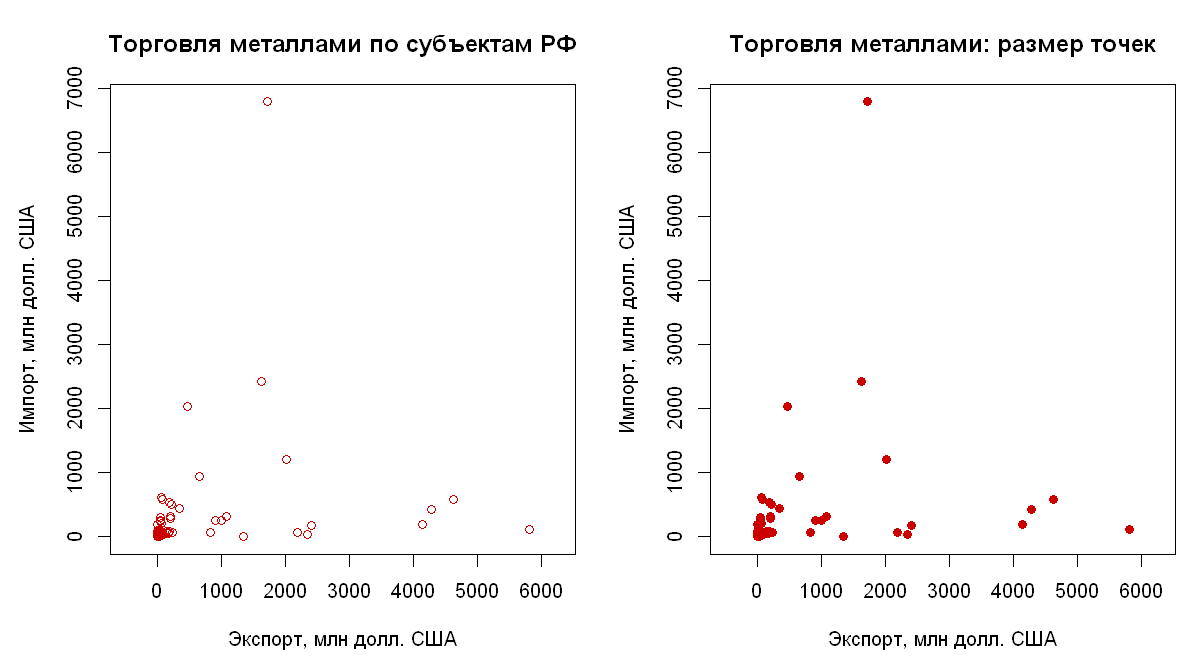

In [2]:
local({
  old <- par(mfrow = c(1, 2), mar = c(4.4, 4.6, 3.5, 1))
  plot(regions$МетЭкспорт, regions$МетИмпорт, asp = 1,
    main = "Торговля металлами по субъектам РФ",
    xlab = "Экспорт, млн долл. США", ylab = "Импорт, млн долл. США",
    col = "red3")
  plot(regions$МетЭкспорт, regions$МетИмпорт, asp = 1,
    main = "Торговля металлами: размер точек",
    xlab = "Экспорт, млн долл. США", ylab = "Импорт, млн долл. США",
    col = "red3", pch = 20, cex = 1.5)
  par(old)
})

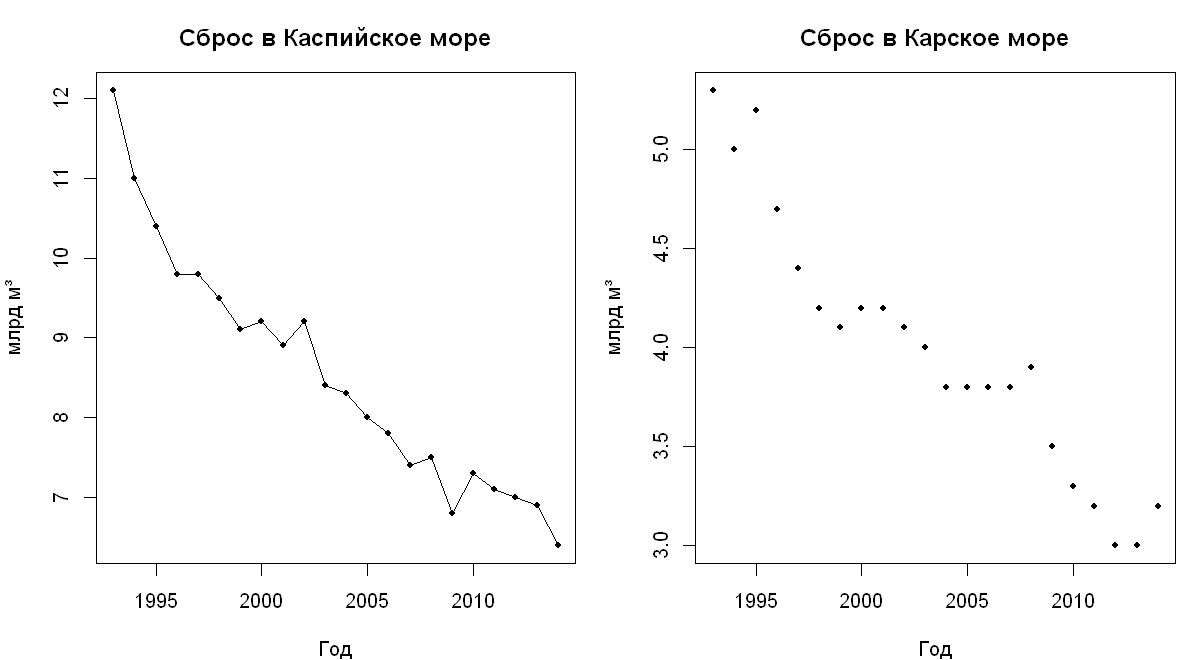

In [3]:
local({
  old <- par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
  plot(water$Год, water$Каспийское, pch = 20,
    main = "Сброс в Каспийское море", xlab = "Год", ylab = "млрд м³")
  lines(water$Год, water$Каспийское)
  plot(water$Год, water$Карское, pch = 20,
    main = "Сброс в Карское море", xlab = "Год", ylab = "млрд м³")
  par(old)
})

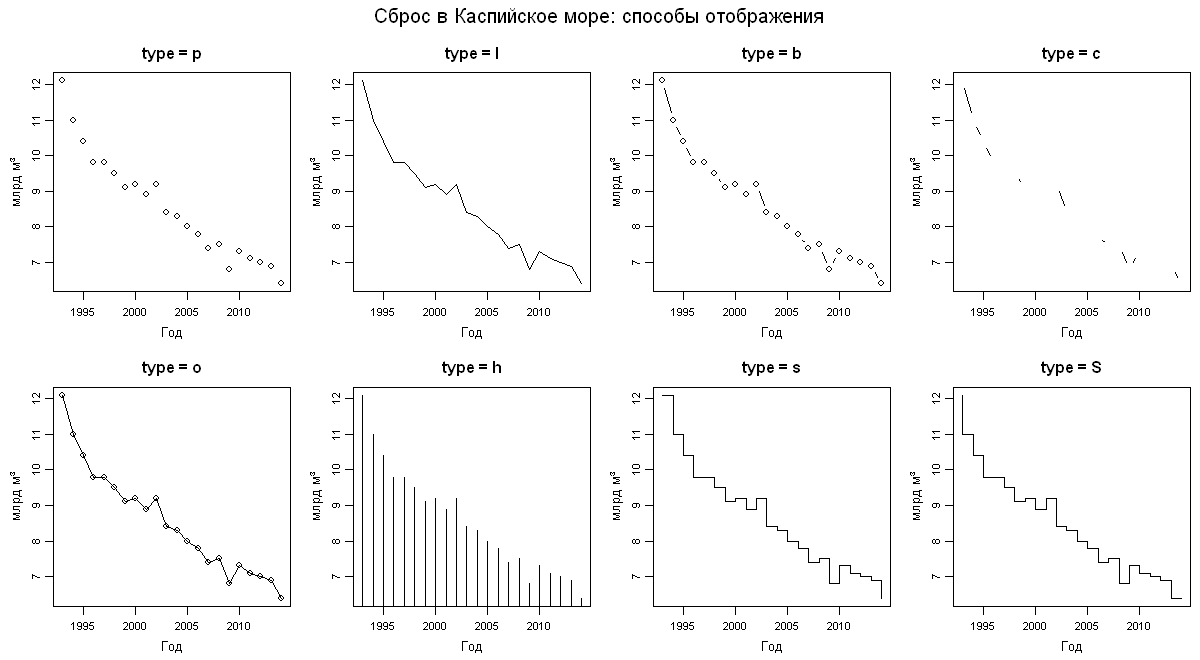

In [4]:
local({
  old <- par(mfrow = c(2, 4), mar = c(3.4, 3.4, 2.6, 0.6),
    oma = c(0, 0, 2, 0), mgp = c(2, 0.7, 0), cex.axis = 0.83)
  for (kind in c("p", "l", "b", "c", "o", "h", "s", "S")) {
    plot(water$Год, water$Каспийское, type = kind,
      main = paste("type =", kind), xlab = "Год", ylab = "млрд м³")
  }
  mtext("Сброс в Каспийское море: способы отображения", side = 3,
    outer = TRUE, line = 0.4)
  par(old)
})

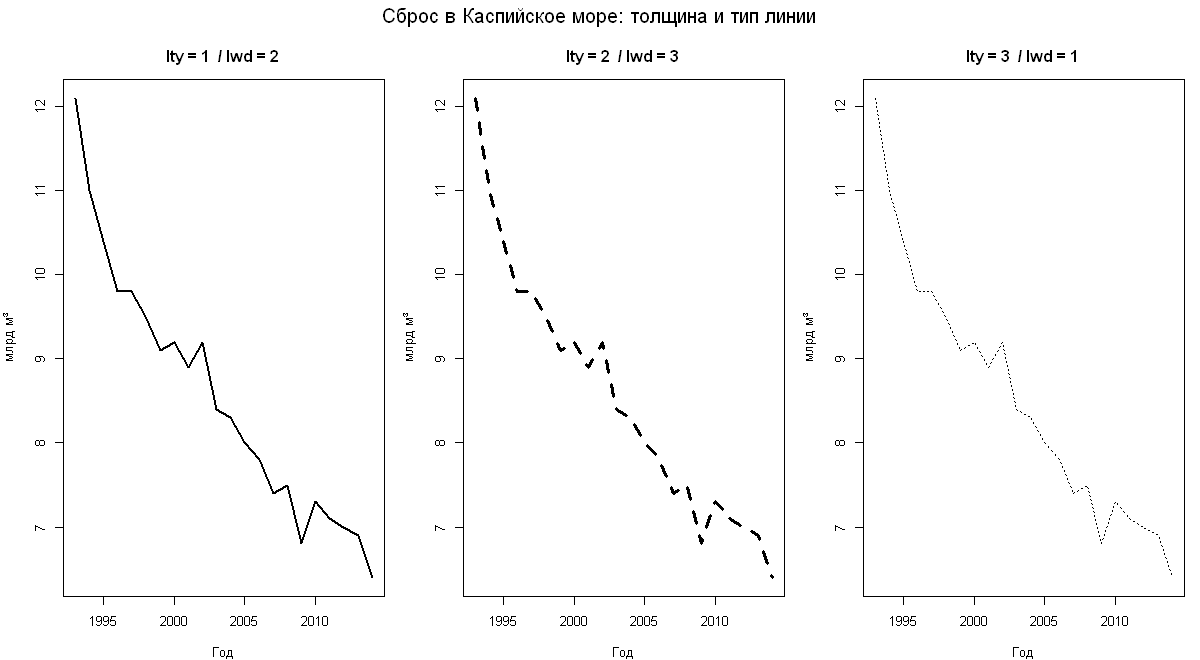

In [5]:
local({
  old <- par(mfrow = c(1, 3), mar = c(4, 4, 3, 1),
    oma = c(0, 0, 2, 0))
  line_widths <- c(2, 3, 1)
  for (style in seq_along(line_widths)) {
    plot(water$Год, water$Каспийское, type = "l",
      lwd = line_widths[style], lty = style,
      main = paste("lty =", style, " / lwd =", line_widths[style]),
      xlab = "Год", ylab = "млрд м³")
  }
  mtext("Сброс в Каспийское море: толщина и тип линии", side = 3,
    outer = TRUE, line = 0.4)
  par(old)
})

### Несколько рядов и размер точки как функция данных

На первом графике добавляем ряд на готовые оси, на втором сначала строим поле, охватывающее все три ряда (рис. 3.6–3.7). В диаграмме рис. 3.8 размер точки зависит от отношения импорта к экспорту того же округа.

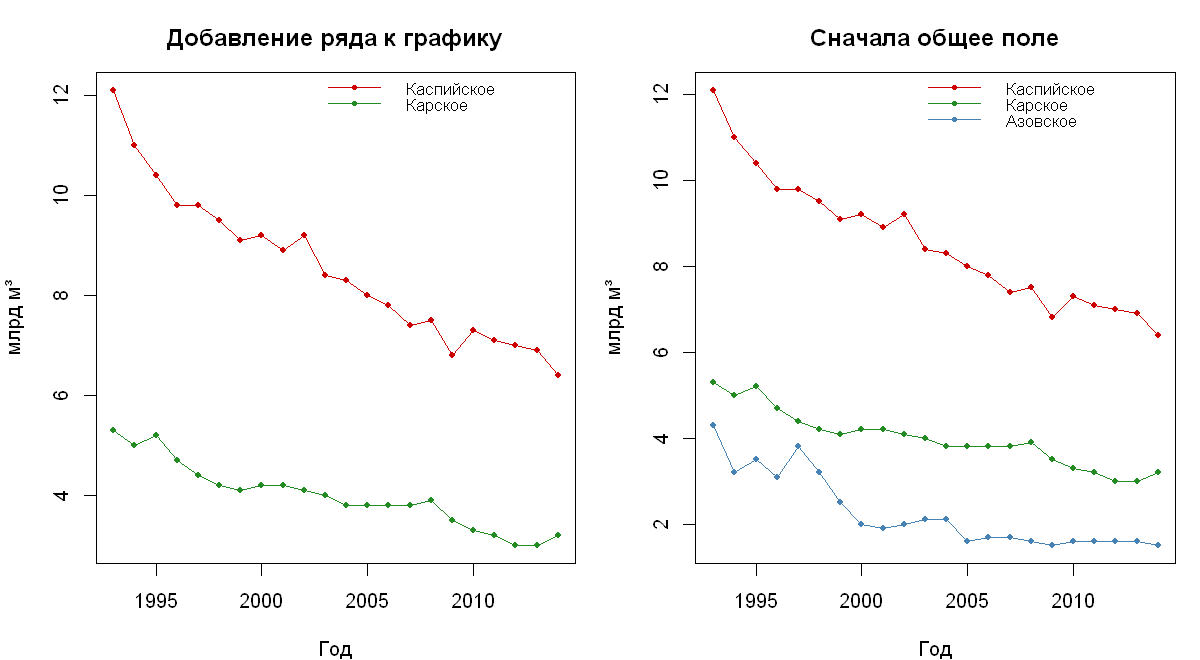

In [6]:
sea_names <- c("Каспийское", "Карское", "Азовское")
sea_colors <- c("red3", "forestgreen", "steelblue")
local({
  old <- par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
  plot(water$Год, water$Каспийское, type = "o", pch = 20,
    col = sea_colors[1], ylim = range(water[sea_names[1:2]]),
    main = "Добавление ряда к графику", xlab = "Год", ylab = "млрд м³")
  points(water$Год, water$Карское, pch = 20, col = sea_colors[2])
  lines(water$Год, water$Карское, col = sea_colors[2])
  legend("topright", sea_names[1:2], col = sea_colors[1:2], pch = 20, lty = 1,
    cex = 0.85, bty = "n")

  plot(range(water$Год), range(water[sea_names]), type = "n",
    main = "Сначала общее поле", xlab = "Год", ylab = "млрд м³")
  for (i in seq_along(sea_names)) {
    points(water$Год, water[[sea_names[i]]], pch = 20, col = sea_colors[i])
    lines(water$Год, water[[sea_names[i]]], col = sea_colors[i])
  }
  legend("topright", sea_names, col = sea_colors, pch = 20, lty = 1,
    cex = 0.85, bty = "n")
  par(old)
})

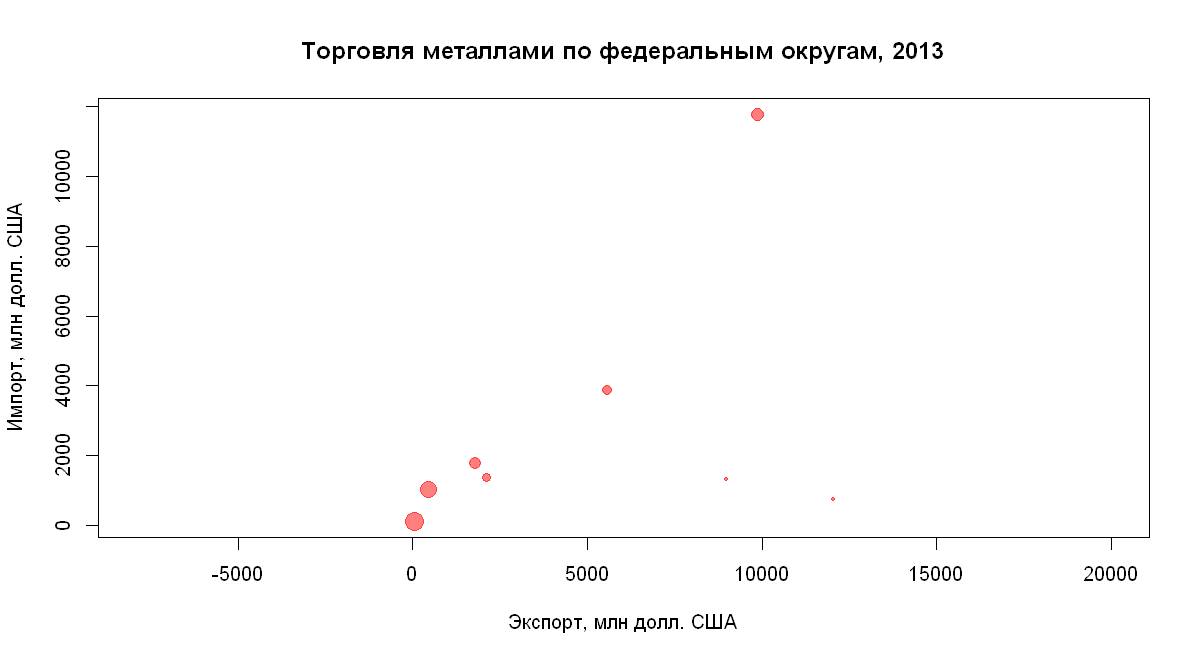

In [7]:
trade_points <- subset(districts, МетЭкспорт > 0 & МетИмпорт > 0)
# Нижняя граница сохраняет видимость точек с малой долей импорта.
point_size <- pmax(0.6, 2 + log(trade_points$МетИмпорт / trade_points$МетЭкспорт))
plot(trade_points$МетЭкспорт, trade_points$МетИмпорт, asp = 1, pch = 20,
  cex = point_size, col = rgb(1, 0, 0, 0.5),
  main = "Торговля металлами по федеральным округам, 2013",
  xlab = "Экспорт, млн долл. США", ylab = "Импорт, млн долл. США")

## 3. Гистограмма и столбчатые диаграммы

Для гистограммы берём продовольственный экспорт (`ПродЭкспорт` из листинга к рис. 3.9) и шаг 100 млн долл. США. Для рис. 3.10–3.12 сравниваем химический экспорт округов в вертикальной и горизонтальной ориентации.

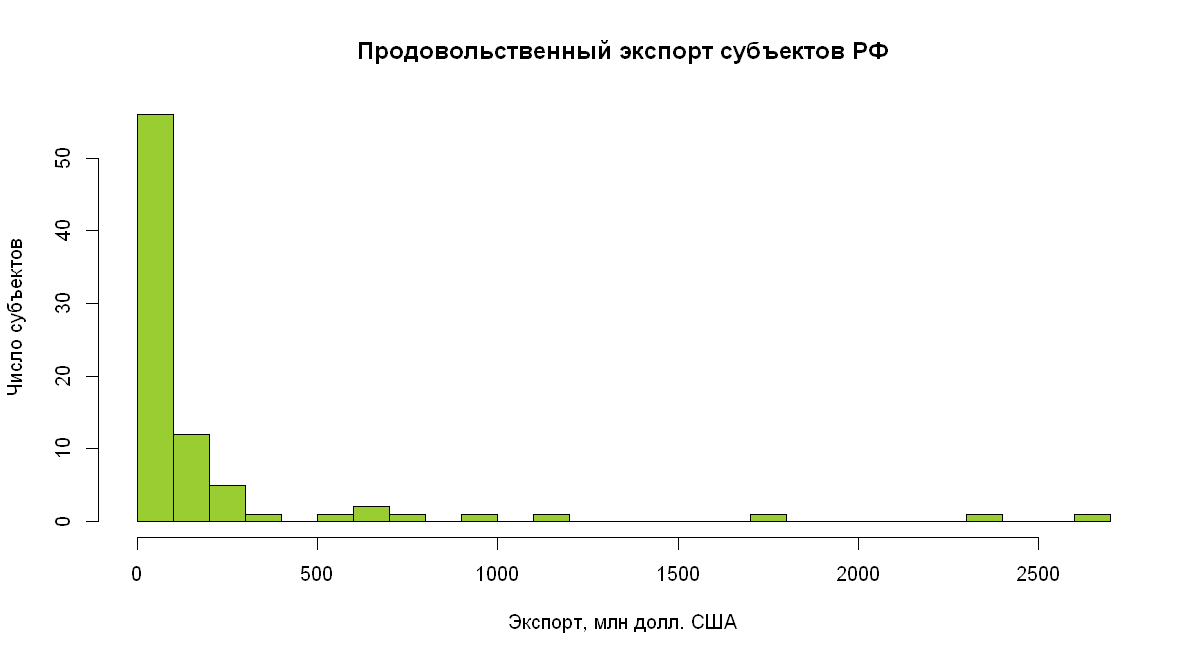

In [8]:
food_exports <- regions$ПродЭкспорт
hist(food_exports,
  breaks = seq(0, ceiling(max(food_exports, na.rm = TRUE) / 100) * 100, by = 100),
  col = "olivedrab3", main = "Продовольственный экспорт субъектов РФ",
  xlab = "Экспорт, млн долл. США", ylab = "Число субъектов")

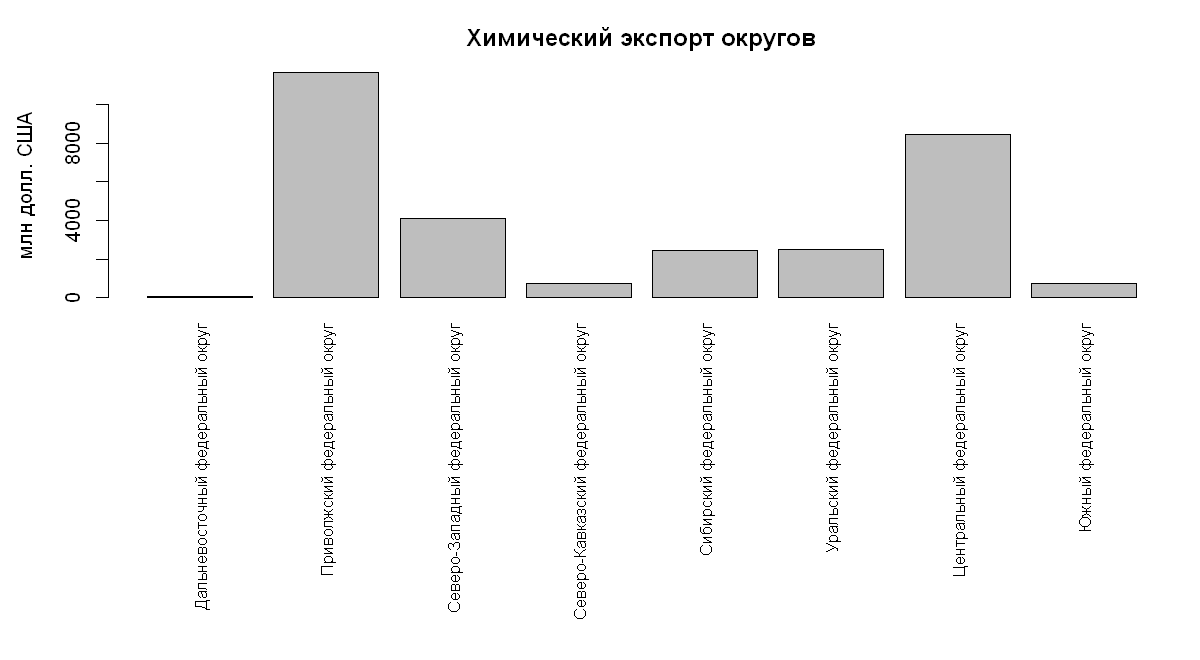

In [9]:
local({
  old <- par(mar = c(15, 4.5, 3, 1))
  barplot(districts$ХимЭкспорт, names.arg = districts$Регион, las = 3,
    cex.names = 0.8, ylab = "млн долл. США", main = "Химический экспорт округов")
  par(old)
})

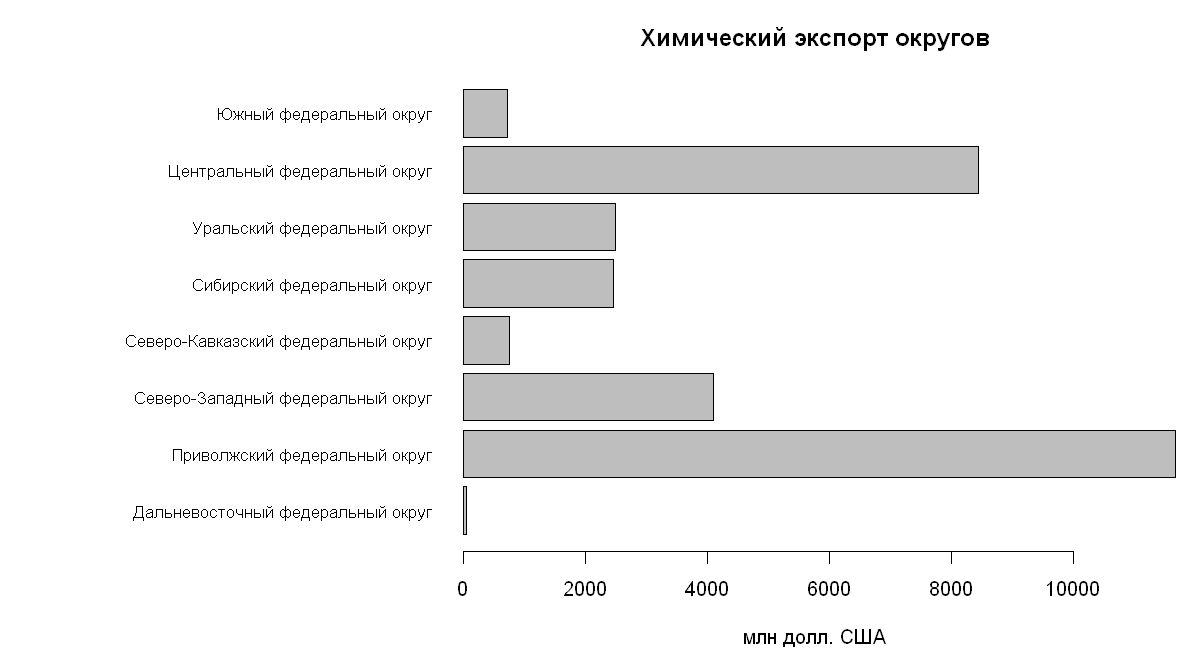

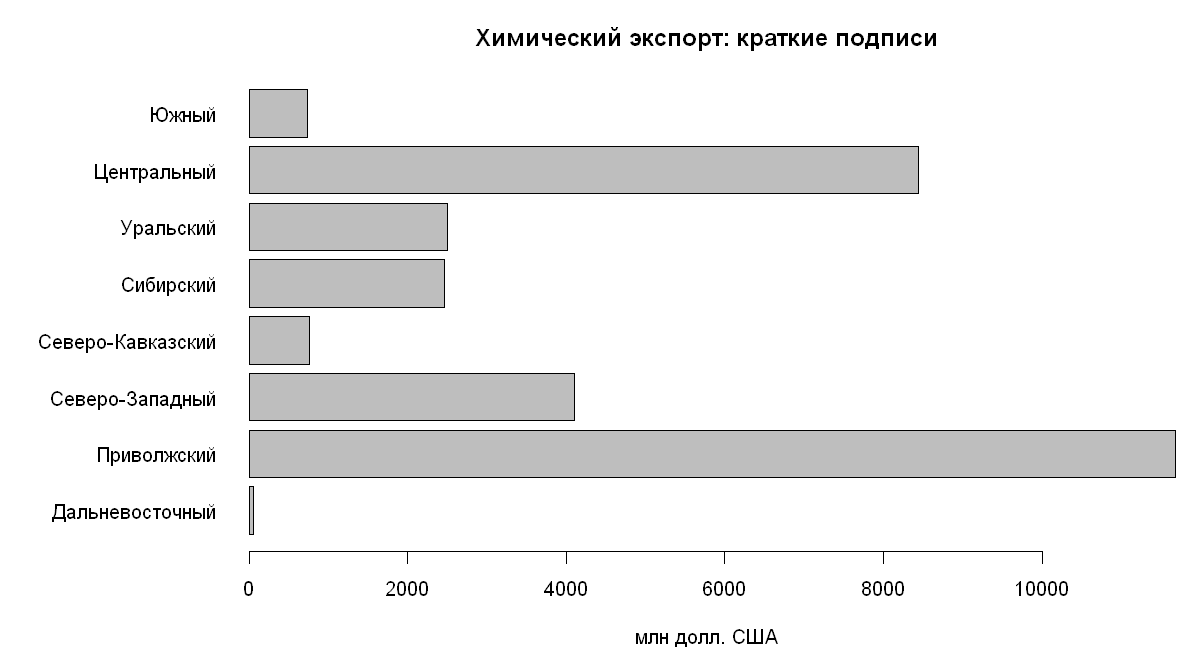

In [10]:
local({
  old <- par(mar = c(4.5, 19, 3, 1))
  barplot(districts$ХимЭкспорт, names.arg = districts$Регион, horiz = TRUE, las = 1,
    cex.names = 0.85, xlab = "млн долл. США", main = "Химический экспорт округов")
  par(mar = c(4.5, 10, 3, 1))
  barplot(districts$ХимЭкспорт, names.arg = district_labels, horiz = TRUE, las = 1,
    xlab = "млн долл. США", main = "Химический экспорт: краткие подписи")
  par(old)
})

## 4. Круговые диаграммы и цвет (§§ 5.4–5.5)

Доля округа равна его экспорту, делённому на сумму экспорта представленных округов. Добавляем подписи, доли и поворот секторов. Сравниваем способы указания цвета и готовые палитры.

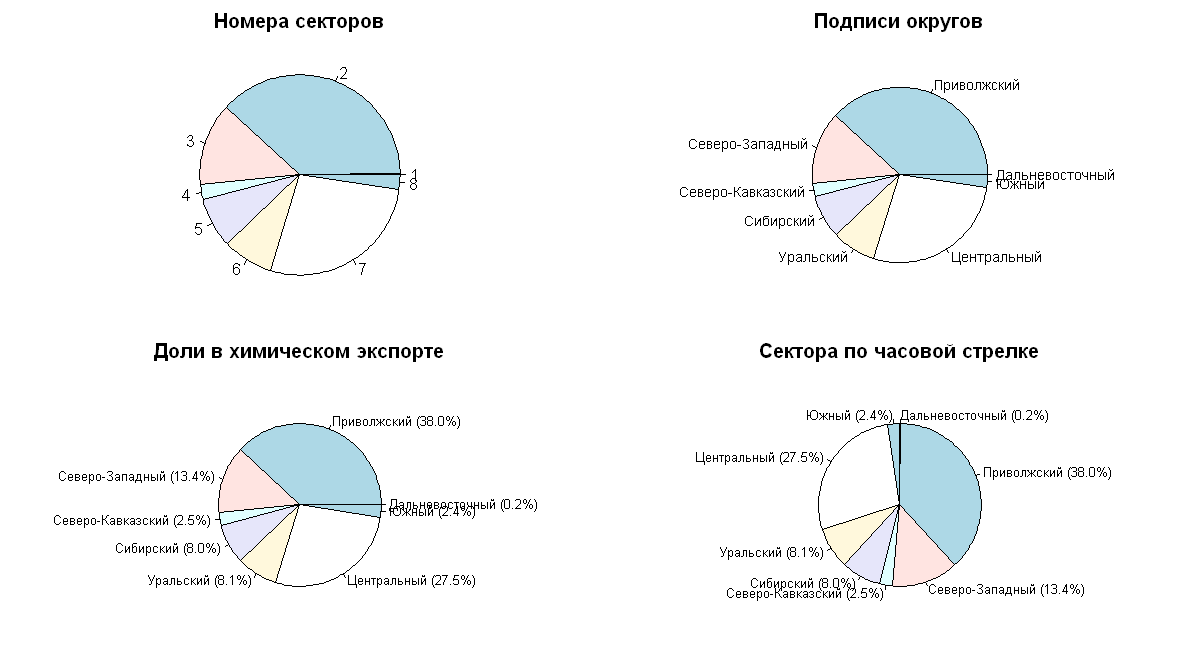

In [11]:
chemical_exports <- districts$ХимЭкспорт
shares <- 100 * chemical_exports / sum(chemical_exports)
pie_labels <- sprintf("%s (%.1f%%)", district_labels, shares)

local({
  old <- par(mfrow = c(2, 2), mar = c(1, 1, 2, 1))
  pie(chemical_exports, main = "Номера секторов")
  pie(chemical_exports, district_labels, radius = 0.7, cex = 0.82,
    main = "Подписи округов")
  pie(chemical_exports, pie_labels, radius = 0.65, cex = 0.77,
    main = "Доли в химическом экспорте")
  pie(chemical_exports, pie_labels, radius = 0.65, cex = 0.77,
    main = "Сектора по часовой стрелке", clockwise = TRUE)
  par(old)
})

[1] "white"         "aliceblue"     "antiquewhite"  "antiquewhite1"
[5] "antiquewhite2" "antiquewhite3"


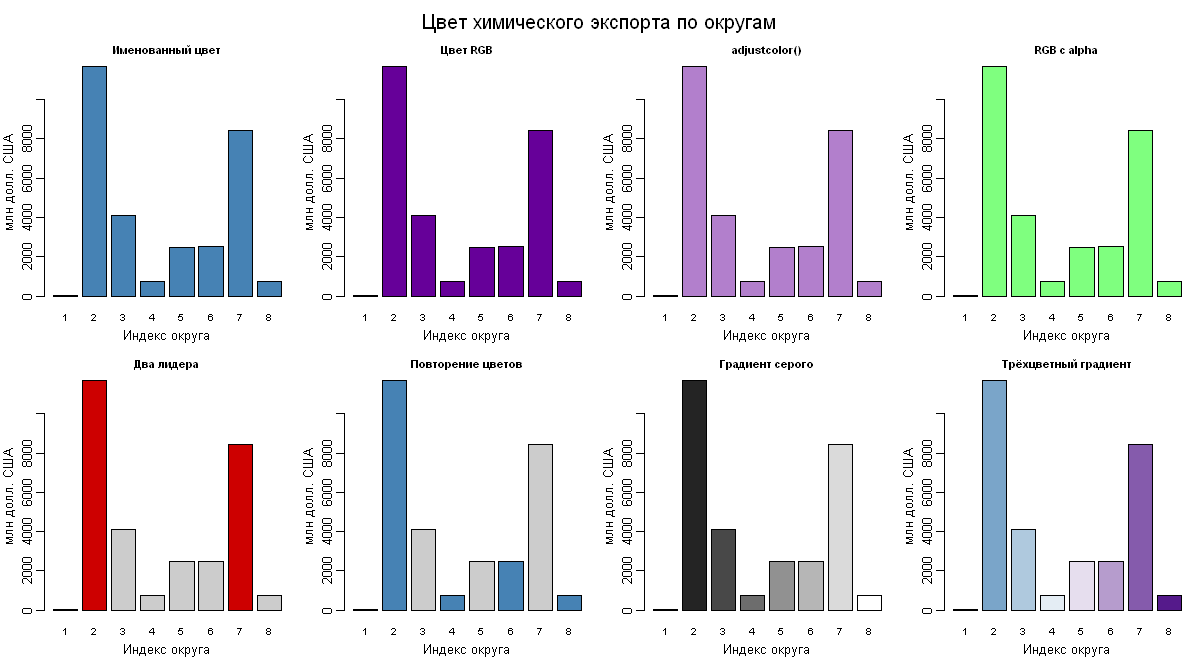

In [12]:
print(head(colors()))
violet <- rgb(0.4, 0, 0.6)
highlight <- rep("grey80", length(chemical_exports))
highlight[order(chemical_exports, decreasing = TRUE)[1:2]] <- "red3"
color_sets <- list(
  "Именованный цвет" = "steelblue",
  "Цвет RGB" = violet,
  "adjustcolor()" = adjustcolor(violet, alpha.f = 0.5),
  "RGB с alpha" = rgb(0, 1, 0, 0.5),
  "Два лидера" = highlight,
  "Повторение цветов" = c("grey80", "steelblue"),
  "Градиент серого" = colorRampPalette(c("black", "white"))(length(chemical_exports)),
  "Трёхцветный градиент" = colorRampPalette(
    c("steelblue", "white", "purple4")
  )(length(chemical_exports))
)

local({
  old <- par(mfrow = c(2, 4), mar = c(3, 2.8, 2.2, 0.6),
    oma = c(0, 0, 2, 0), mgp = c(1.8, 0.6, 0))
  for (label in names(color_sets)) {
    barplot(chemical_exports, col = color_sets[[label]], main = label,
      xlab = "Индекс округа", ylab = "млн долл. США", cex.main = 0.86,
      names.arg = seq_along(chemical_exports), cex.names = 0.75)
  }
  mtext("Цвет химического экспорта по округам", side = 3, outer = TRUE)
  par(old)
})

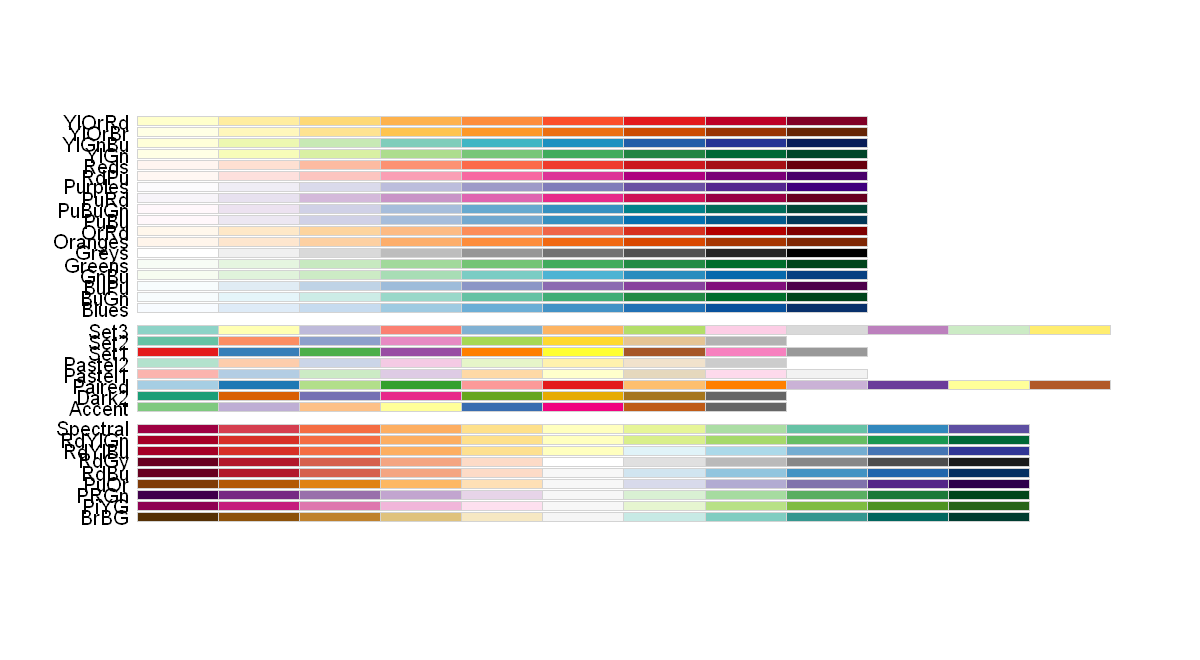

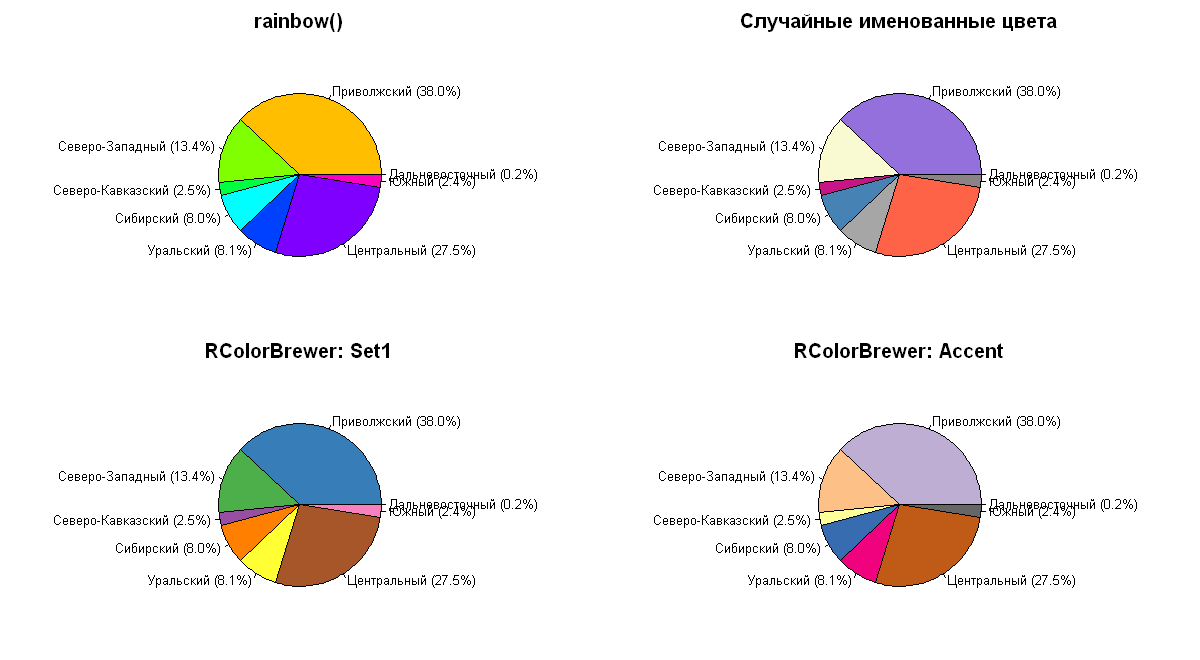

In [13]:
RColorBrewer::display.brewer.all()
local({
  old <- par(mfrow = c(2, 2), mar = c(1, 1, 2, 1))
  n <- length(chemical_exports)
  set.seed(7)
  pie_colors <- list(
    "rainbow()" = rainbow(n),
    "Случайные именованные цвета" = sample(colors(), n),
    "RColorBrewer: Set1" = RColorBrewer::brewer.pal(n, "Set1"),
    "RColorBrewer: Accent" = RColorBrewer::brewer.pal(n, "Accent")
  )
  for (label in names(pie_colors)) {
    pie(chemical_exports, pie_labels, col = pie_colors[[label]],
      radius = 0.65, cex = 0.77, main = label)
  }
  par(old)
})

## 5. Настройки отображения и легенда (§§ 5.6–5.7)

Добавляем оси, рамку, сетку и подпись точки. Для тех же трёх морей показываем два способа задания легенды: цветные плашки и образцы линий с точками.

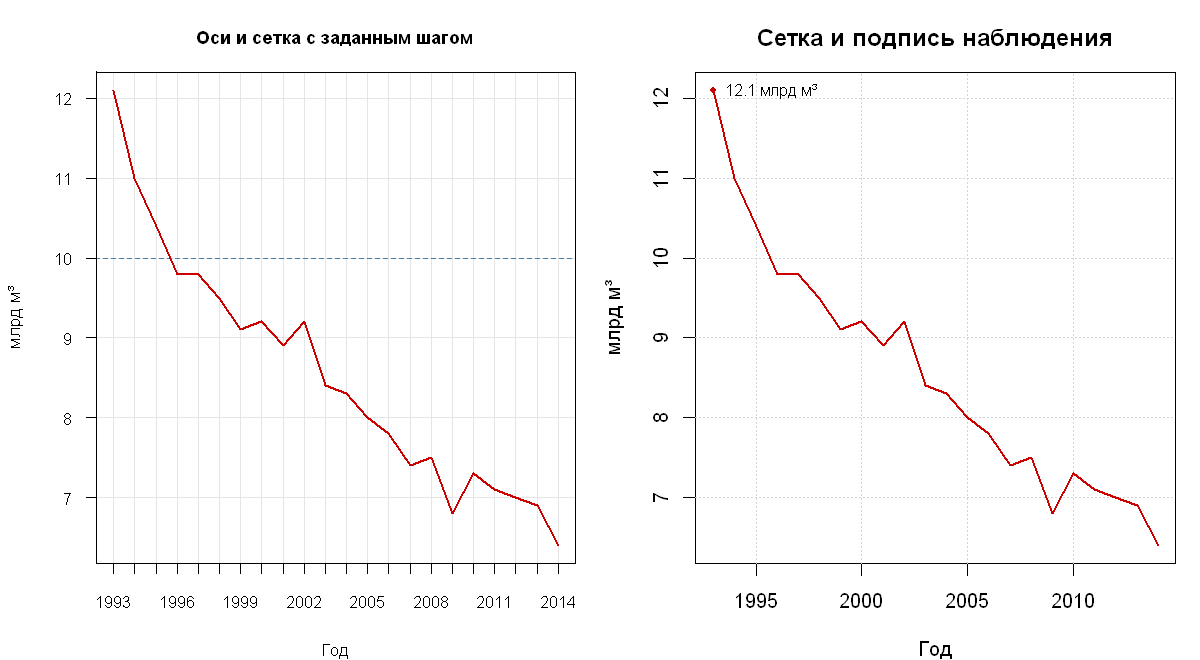

In [14]:
local({
  old <- par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
  years <- seq(min(water$Год), max(water$Год))
  volume_ticks <- seq(floor(min(water$Каспийское)), ceiling(max(water$Каспийское)))
  plot(water$Год, water$Каспийское, type = "n", axes = FALSE,
    main = "Оси и сетка с заданным шагом",
    xlab = "Год", ylab = "млрд м³", cex.lab = 0.85, cex.main = 0.9)
  axis(1, at = years, labels = FALSE, tck = -0.02)
  axis(1, at = years[seq(1L, length(years), by = 3L)], tck = 0, cex.axis = 0.8)
  axis(2, at = volume_ticks, las = 1, tck = -0.02, cex.axis = 0.8)
  abline(v = years, h = volume_ticks, col = "grey90")
  abline(h = 10, col = "steelblue", lty = 2)
  lines(water$Год, water$Каспийское, col = "red3", lwd = 2)
  box()

  plot(water$Год, water$Каспийское, type = "n",
    main = "Сетка и подпись наблюдения", xlab = "Год", ylab = "млрд м³")
  grid()
  lines(water$Год, water$Каспийское, col = "red3", lwd = 2)
  maximum <- which.max(water$Каспийское)
  points(water$Год[maximum], water$Каспийское[maximum], pch = 20, col = "red3")
  text(water$Год[maximum], water$Каспийское[maximum],
    labels = sprintf("%.1f млрд м³", water$Каспийское[maximum]), pos = 4, cex = 0.82)
  par(old)
})

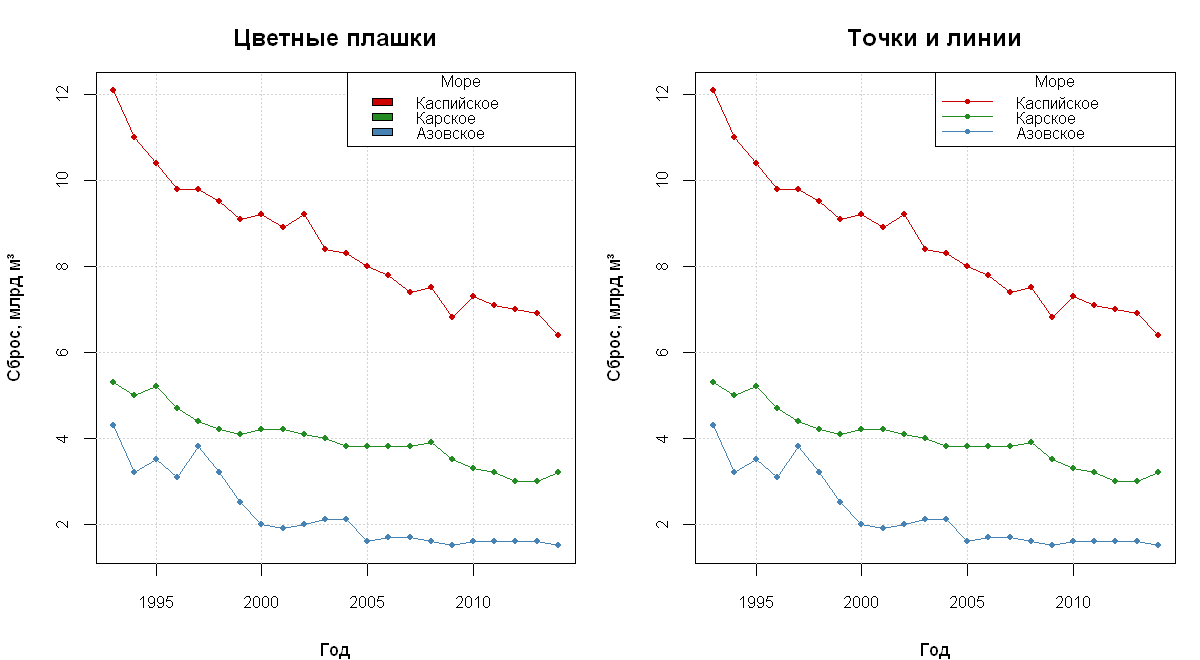

In [15]:
local({
  old <- par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
  for (kind in c("Цветные плашки", "Точки и линии")) {
    plot(range(water$Год), range(water[sea_names]), type = "n",
      main = kind, xlab = "Год", ylab = "Сброс, млрд м³",
      cex.axis = 0.85, cex.lab = 0.9)
    grid()
    for (i in seq_along(sea_names)) {
      lines(water$Год, water[[sea_names[i]]], type = "o",
        col = sea_colors[i], pch = 20)
    }
    if (kind == "Цветные плашки") {
      legend("topright", sea_names, title = "Море", fill = sea_colors, cex = 0.8)
    } else {
      legend("topright", sea_names, title = "Море", col = sea_colors,
        pch = 20, lty = 1, lwd = 1, cex = 0.8)
    }
  }
  par(old)
})

## 6. Встроенные данные варианта: население Австралии

Показываем исходный уровень и квартальное изменение численности. Разность относится к кварталу второго наблюдения, поэтому для первого квартала данных о приросте нет. Исходный ряд измерен в тысячах человек и содержит 89 наблюдений со II квартала 1971 по II квартал 1993 года по индексам объекта R. [Описание `austres`](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/austres.html)

quarters,first_thousands,last_thousands,total_growth_thousands
<int>,<dbl>,<dbl>,<dbl>
89,13067.3,17661.5,4594.2


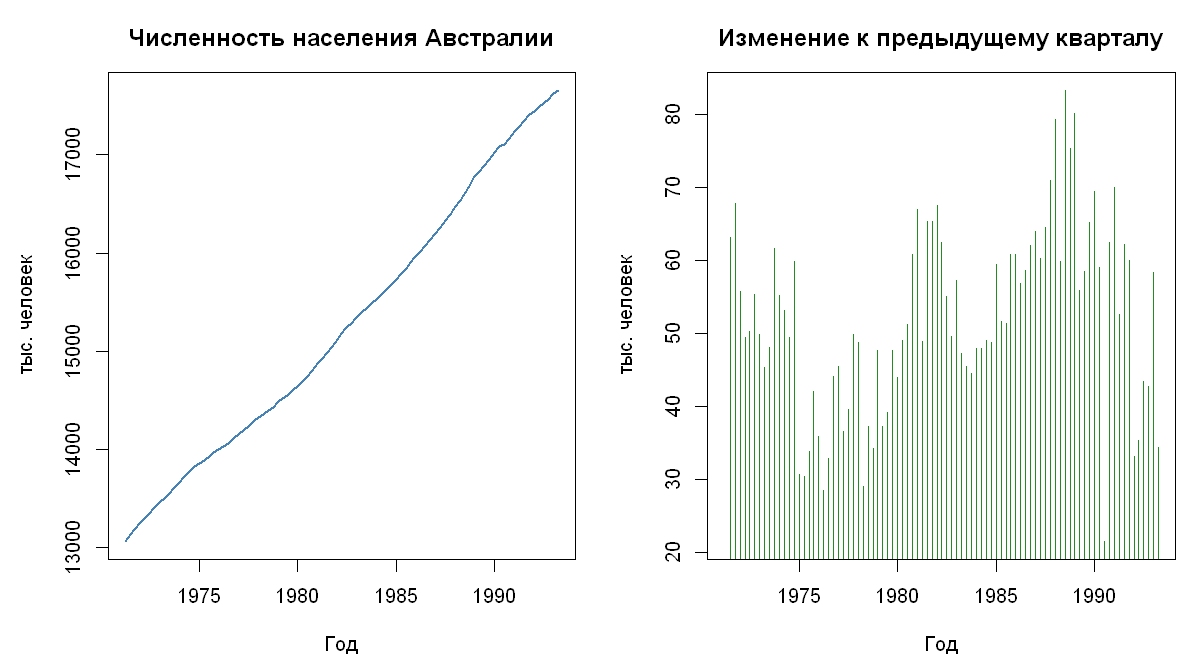

In [16]:
population_ts <- datasets::austres
population <- data.frame(
  time = as.numeric(time(population_ts)),
  year = as.integer(time(population_ts)),
  quarter = as.integer(cycle(population_ts)),
  population_thousands = as.numeric(population_ts)
) |>
  mutate(change_thousands = population_thousands - lag(population_thousands))

local({
  old <- par(mfrow = c(1, 2), mar = c(4.2, 4.5, 3, 1))
  plot(population$time, population$population_thousands, type = "l", lwd = 2,
    col = "steelblue", main = "Численность населения Австралии",
    xlab = "Год", ylab = "тыс. человек")
  plot(population$time, population$change_thousands, type = "h",
    col = "forestgreen", main = "Изменение к предыдущему кварталу",
    xlab = "Год", ylab = "тыс. человек")
  abline(h = 0, col = "grey65")
  par(old)
})

population |>
  summarise(
    quarters = n(),
    first_thousands = first(population_thousands),
    last_thousands = last(population_thousands),
    total_growth_thousands = last(population_thousands) - first(population_thousands)
  )

## 7. Внешние данные варианта: анкеты Stack Overflow за 2022 год

Показываем ведущие страны по числу ответов, распределение стажа по заполненным ответам и языки, которые участники указали за последний год. Для каждого языка одна анкета учитывается один раз. Участник мог указать несколько языков.

In [17]:
# Читает локальную или опубликованную таблицу ответов за 2022 год.
# Возвращает таблицу и имя фактически использованного источника.
read_survey_2022 <- function() {
  csv_paths <- c(
    Sys.getenv("ITAIOD_SURVEY_CSV"),
    "2022_survey_results_public.csv", "survey_results_public.csv",
    "../data/2022_survey_results_public.csv", "../data/survey_results_public.csv"
  )
  csv_paths <- csv_paths[file.exists(csv_paths)]
  if (length(csv_paths) > 0L) {
    path <- csv_paths[[1L]]
    return(list(
      data = read.csv(path, na.strings = c("", "NA"), fileEncoding = "UTF-8"),
      source = path
    ))
  }

  official_url <- paste0(
    "https://media.githubusercontent.com/media/StackExchange/Survey/",
    "main/packages/archive/2022/results.csv"
  )
  path <- tempfile(fileext = ".csv")
  on.exit(unlink(path))
  download.file(official_url, path, mode = "wb", quiet = TRUE)
  list(
    data = read.csv(path, na.strings = c("", "NA"), fileEncoding = "UTF-8"),
    source = official_url
  )
}

survey_import <- read_survey_2022()
survey <- survey_import$data
survey_columns <- c("ResponseId", "Country", "WorkExp", "LanguageHaveWorkedWith")
stopifnot(
  all(survey_columns %in% names(survey)),
  nrow(survey) == 73268L,
  anyDuplicated(survey$ResponseId) == 0L,
  is.numeric(survey$WorkExp)
)
cat("Источник:", survey_import$source, "\n")
cat("Ответов:", nrow(survey), "\n")

Источник: D:\sem7\tmp\itaiod-runtime\results.csv 


Ответов: 73268 


In [18]:
countries <- survey |>
  filter(!is.na(Country)) |>
  count(Country, name = "responses", sort = TRUE) |>
  slice_head(n = 8)
country_labels <- sub(
  "United Kingdom of Great Britain and Northern Ireland", "United Kingdom",
  countries$Country, fixed = TRUE
)
country_labels <- sub("United States of America", "United States", country_labels, fixed = TRUE)

work_experience <- survey |>
  filter(is.finite(WorkExp), WorkExp >= 0) |>
  pull(WorkExp)
stopifnot(nrow(countries) > 0L, length(work_experience) > 0L)

answered <- survey$LanguageHaveWorkedWith[!is.na(survey$LanguageHaveWorkedWith)]
languages_per_response <- strsplit(answered, ";", fixed = TRUE)
language_counts <- sort(
  table(unlist(lapply(languages_per_response, unique), use.names = FALSE)),
  decreasing = TRUE
)
top_languages <- head(language_counts, 8)
stopifnot(length(top_languages) > 0L)

print(countries)
print(summary(work_experience))
data.frame(
  language = names(top_languages),
  responses = as.integer(top_languages),
  percent_of_answered = round(100 * as.numeric(top_languages) / length(answered), 1)
)

                                               Country responses
1                             United States of America     13543
2                                                India      6639
3                                              Germany      5395
4 United Kingdom of Great Britain and Northern Ireland      4190
5                                               Canada      2490
6                                               France      2328
7                                               Brazil      2109
8                                               Poland      1732


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    4.00    8.00   10.24   15.00   50.00 


language,responses,percent_of_answered
<chr>,<int>,<dbl>
JavaScript,46443,65.4
HTML/CSS,39142,55.1
SQL,35127,49.5
Python,34155,48.1
TypeScript,24752,34.9
Java,23644,33.3
Bash/Shell,20656,29.1
C#,19883,28.0


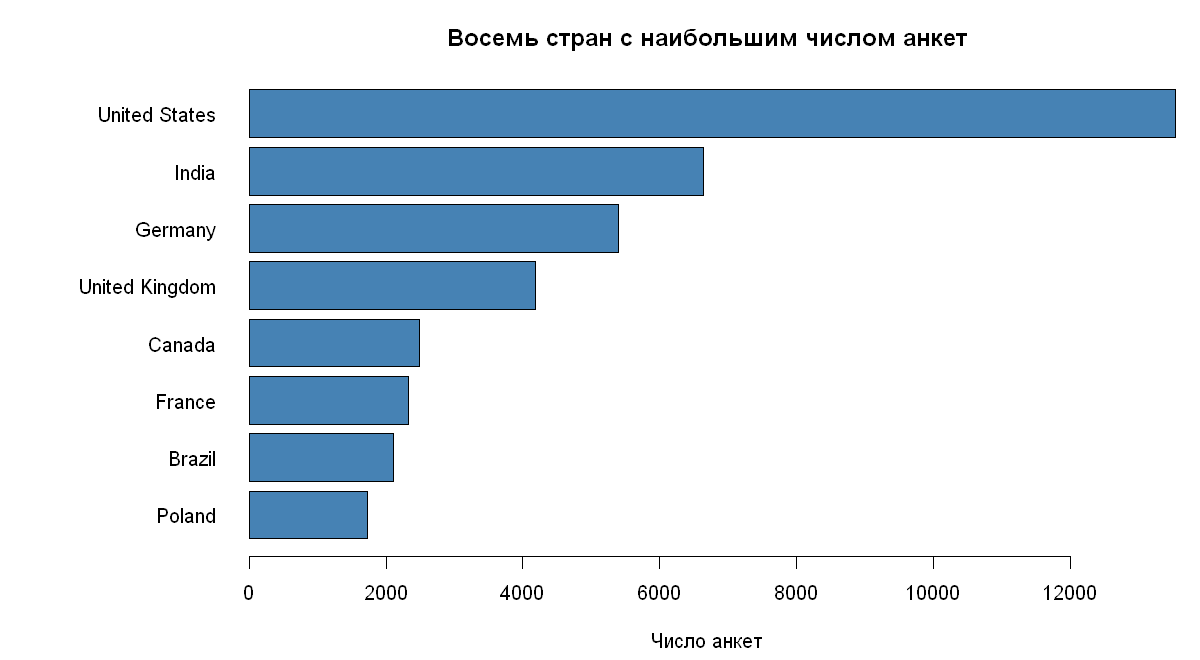

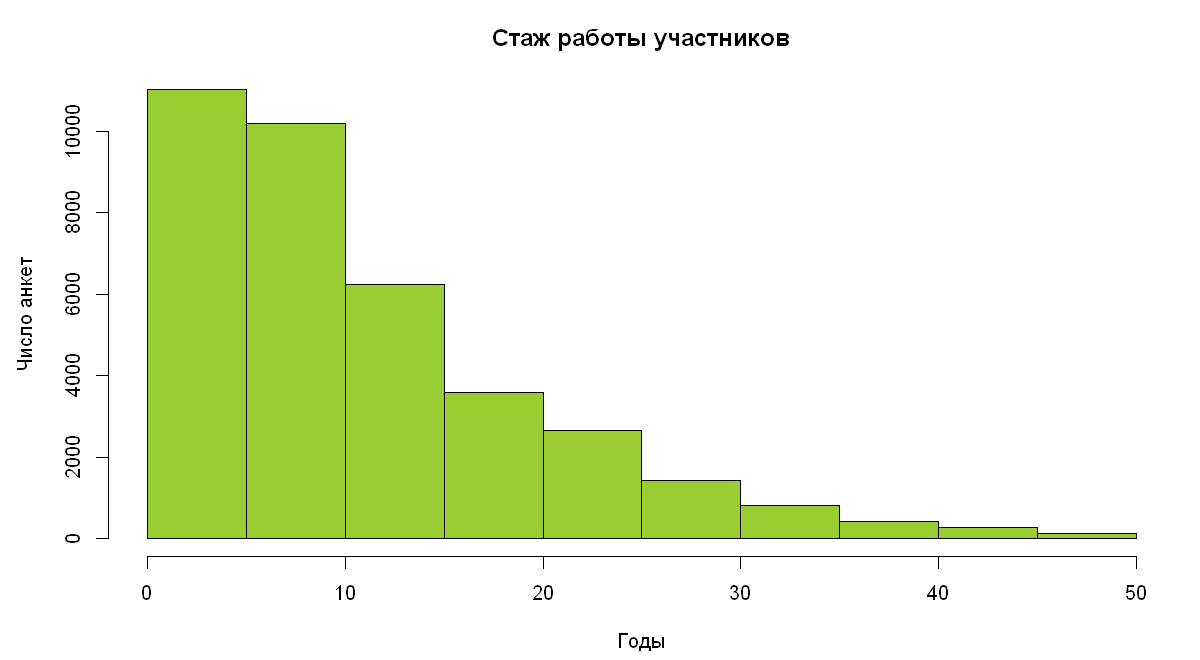

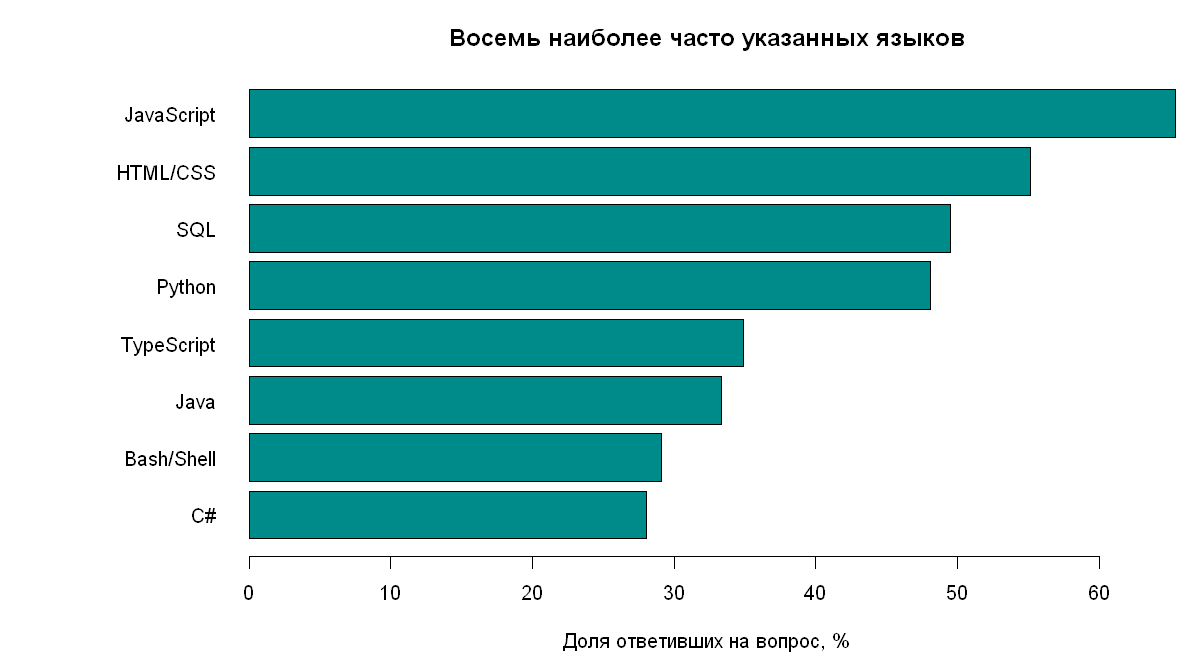

In [19]:
local({
  old <- par(mar = c(4.3, 10, 3, 1))
  barplot(rev(countries$responses), names.arg = rev(country_labels),
    horiz = TRUE, las = 1, col = "steelblue",
    main = "Восемь стран с наибольшим числом анкет", xlab = "Число анкет")
  par(mar = c(4.3, 4.5, 3, 1))
  hist(work_experience,
    breaks = seq(0, max(5, ceiling(max(work_experience) / 5) * 5), by = 5),
    right = FALSE, include.lowest = TRUE, col = "olivedrab3",
    main = "Стаж работы участников", xlab = "Годы", ylab = "Число анкет")
  par(mar = c(4.3, 10, 3, 1))
  barplot(100 * rev(as.numeric(top_languages)) / length(answered),
    names.arg = rev(names(top_languages)), horiz = TRUE, las = 1, col = "darkcyan",
    main = "Восемь наиболее часто указанных языков",
    xlab = "Доля ответивших на вопрос, %")
  par(old)
})

In [20]:
cat(sprintf(
  "Больше всего анкет в волне 2022 из страны %s (%d).\n",
  country_labels[1L], countries$responses[1L]
))
cat(sprintf(
  "Медиана стажа среди %d ответивших составляет %.1f года.\n",
  length(work_experience), median(work_experience)
))
cat(sprintf(
  "Чаще всего указывали %s: %d из %d ответивших на вопрос.\n",
  names(top_languages)[1L], as.integer(top_languages[1L]), length(answered)
))

Больше всего анкет в волне 2022 из страны United States (13543).


Медиана стажа среди 36769 ответивших составляет 8.0 года.


Чаще всего указывали JavaScript: 46443 из 70975 ответивших на вопрос.


Число анкет зависит от состава участников опроса. Проценты по языкам считаются от числа ответивших на этот вопрос и при множественном выборе могут в сумме превышать 100%.

## Контрольные вопросы

| № | Ответ |
|---|---|
| 1–4 | `plot()` строит стандартный график, `barplot()` — столбчатую диаграмму, `pie()` — секторную, `hist()` — гистограмму. Интервалы гистограммы задают через `breaks`. Столбцы поворачивают с `horiz = TRUE`. |
| 5–8 | Графические параметры устанавливает `par()`. Поля задают через `mar` в порядке низ, лево, верх, право. `las = 2` ставит подписи перпендикулярно осям. Большое положительное значение `options(scipen = ...)` делает обычную запись чисел предпочтительной. |
| 9–12 | Цвет задаёт `col`, толщину и стиль линии — `lwd` и `lty`, размер и форму точки — `cex` и `pch`. На существующие оси добавляют `points()` и `lines()`. |
| 13–16 | Рамку рисует `box()`, сетку — `grid()`, одинаковый масштаб даёт `asp = 1`. Для масштаба подписей используют `cex.axis`, `cex.lab`, `cex.main` и `cex.sub`. |
| 17–20 | Цвет задают именем, HEX-кодом, номером в палитре или функциями `rgb()`, `hsv()`, `hcl()`. Прозрачность регулируют `alpha` и `adjustcolor()`. Примеры палитр — `rainbow()`, `heat.colors()`, `topo.colors()`, `terrain.colors()`, `hcl.colors()`. Для интерполяции между опорными цветами используют `colorRampPalette()`. |
| 21–22 | `legend()` строит легенду. Точки задают через `pch`, линии — через `lty` и `lwd`. |